In [1]:
# Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import kruskal
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load dataset

In [5]:
df = pd.read_csv(
    "/home/anurag/Codes_7th_Sem/BI/BIDatasets/Assign4/agricultural_genomics.csv",
    low_memory=False
)

print("AGRICULTURAL GENOMICS AND CROP IMPROVEMENT")
print("Dataset Shape:", df.shape)
print(df.iloc[:, :8].head())

AGRICULTURAL GENOMICS AND CROP IMPROVEMENT
Dataset Shape: (311, 11614)
  Genotype  Final Anthracnose Severity  rAUDPC 2208353_F_0-31_T_C-31_T_C  \
0   200306                        48.3      61                       NaN   
1   238396                        34.5      45                        TT   
2    71644                        39.5      50                        TT   
3    71711                        48.2      47                        TT   
4    75123                        49.5      47                       NaN   

  2208353_F_0-51_C_T-51_C_T 1954669_F_0-49_A_T-49_A_T  \
0                       NaN                        TT   
1                        CC                        TT   
2                        CC                        TT   
3                        CC                       NaN   
4                       NaN                        TT   

  2647588_F_0-20_C_G-20_C_G 2224806_F_0-14_T_G-14_T_G  
0                        CG                        TT  
1                

In [4]:
# 2. IDENTIFY TRAITS AND GENETIC MARKERS

In [6]:
required_traits = ["Final Anthracnose Severity", "rAUDPC"]
df[required_traits] = df[required_traits].apply(
    pd.to_numeric, errors="coerce"
)

marker_columns = [
    c for c in df.columns if c not in ["Genotype"] + required_traits
]

print("Samples:", len(df))
print("SNP Markers:", len(marker_columns))
print(df[required_traits].describe())

Samples: 311
SNP Markers: 11611
       Final Anthracnose Severity      rAUDPC
count                  311.000000  311.000000
mean                    42.415434   47.209003
std                     12.421296   13.132994
min                     18.500000   21.000000
25%                     32.300000   37.000000
50%                     41.800000   45.000000
75%                     51.850000   54.000000
max                     75.300000   91.000000


In [7]:
# 3. DATA CLEANING

In [8]:
df = df.drop_duplicates(subset="Genotype").copy()

missing_codes = ["", "N", "NN", "NA", "N/A", "NAN",
                 "NONE", "NULL", "-", "--", "?"]

In [9]:
for col in marker_columns:
    df[col] = df[col].astype("string").str.strip().str.upper()
    df[col] = df[col].replace(missing_codes, pd.NA)

marker_columns = [
    c for c in marker_columns
    if df[c].notna().sum() > 0 and df[c].nunique() > 1
]

print("\nAfter Cleaning")
print("Samples:", len(df))
print("Usable SNP Markers:", len(marker_columns))
print("Missing SNP Call Rate:",
      round(df[marker_columns].isna().mean().mean() * 100, 2), "%")


After Cleaning
Samples: 311
Usable SNP Markers: 11611
Missing SNP Call Rate: 14.34 %


In [10]:
# 4. DISEASE RESISTANCE ANALYSIS
print("\nDISEASE RESISTANCE ANALYSIS")

for trait in required_traits:
    print("\n", trait)
    print("Mean:", round(df[trait].mean(), 2))
    print("Median:", round(df[trait].median(), 2))
    print("Minimum:", df[trait].min())
    print("Maximum:", df[trait].max())


DISEASE RESISTANCE ANALYSIS

 Final Anthracnose Severity
Mean: 42.42
Median: 41.8
Minimum: 18.5
Maximum: 75.3

 rAUDPC
Mean: 47.21
Median: 45.0
Minimum: 21
Maximum: 91


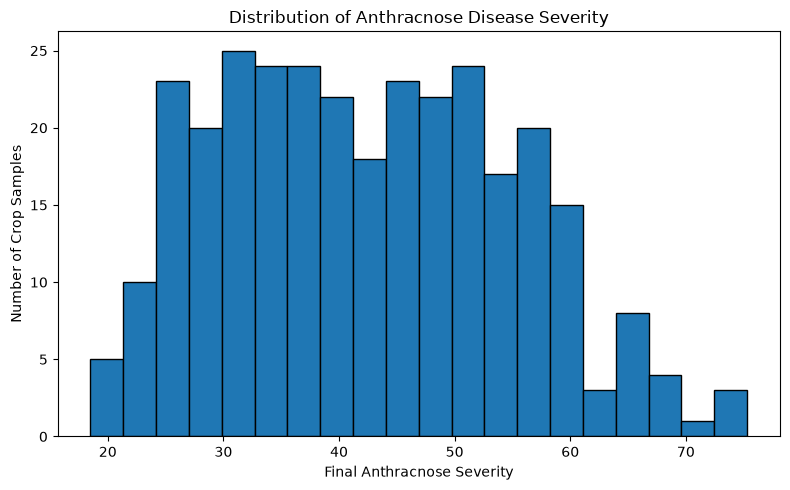

In [11]:
# GRAPH 1: DISEASE SEVERITY DISTRIBUTION
plt.figure(figsize=(8, 5))
plt.hist(df[required_traits[0]].dropna(), bins=20,
         edgecolor="black")
plt.xlabel("Final Anthracnose Severity")
plt.ylabel("Number of Crop Samples")
plt.title("Distribution of Anthracnose Disease Severity")
plt.tight_layout()
plt.show()

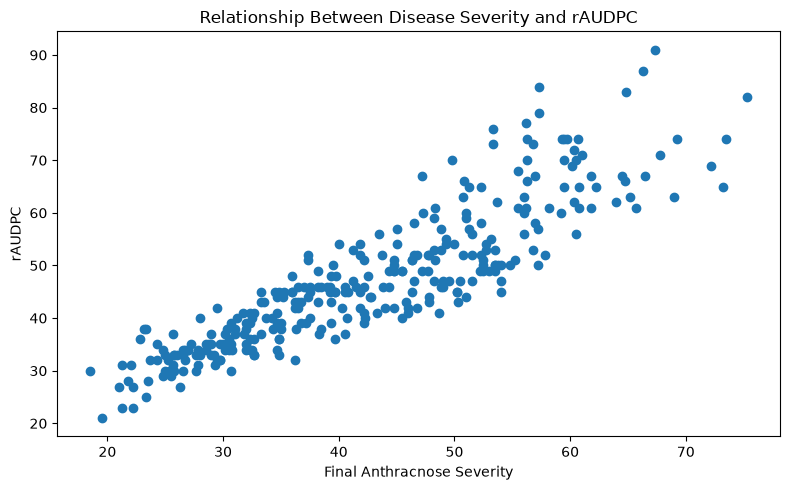

Correlation: 0.888


In [12]:
# GRAPH 2: RELATIONSHIP BETWEEN DISEASE TRAITS
plt.figure(figsize=(8, 5))
plt.scatter(df[required_traits[0]], df["rAUDPC"])
plt.xlabel("Final Anthracnose Severity")
plt.ylabel("rAUDPC")
plt.title("Relationship Between Disease Severity and rAUDPC")
plt.tight_layout()
plt.show()

print("Correlation:",
      round(df[required_traits[0]].corr(df["rAUDPC"]), 3))

In [15]:
# 5. SNP ASSOCIATION USING KRUSKAL-WALLIS TEST
def benjamini_hochberg(p):
    p = np.asarray(p)
    n = len(p)
    if n == 0:
        return np.array([])

    order = np.argsort(p)
    adjusted = p[order] * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    result = np.empty(n)
    result[order] = np.clip(adjusted, 0, 1)
    return result


association_results = []

for trait in required_traits:
    results = []

    for marker in marker_columns:
        temp = df[[marker, trait]].dropna()

        if len(temp) < 10 or temp[marker].nunique() < 2:
            continue

        groups = [g[trait].values for _, g in temp.groupby(marker)
                  if len(g) >= 3]

        if len(groups) < 2:
            continue

        try:
            h, p = kruskal(*groups)

            if np.isfinite(p):
                results.append({
                    "Trait": trait,
                    "SNP_Marker": marker,
                    "Kruskal_Wallis_H": h,
                    "P_Value": p,
                    "Samples_Tested": len(temp),
                    "Genotype_Groups": len(groups)
                })
        except ValueError:
            continue

    if results:
        result_df = pd.DataFrame(results)
        result_df["Adjusted_P_Value"] = benjamini_hochberg(
            result_df["P_Value"]
        )
        association_results.append(result_df)

In [14]:
# DISPLAY AND SAVE ASSOCIATION RESULTS
if association_results:
    association_df = pd.concat(association_results, ignore_index=True)
    association_df = association_df.sort_values(
        ["Trait", "Adjusted_P_Value", "P_Value"]
    )

    for trait in required_traits:
        top = association_df[association_df["Trait"] == trait].head(10)
        print("\nTop SNP Associations:", trait)
        print(top.to_string(index=False) if not top.empty
              else "No eligible SNP markers found.")

    significant = association_df[
        association_df["Adjusted_P_Value"] < 0.05
    ]
    print("\nSignificant Markers:", len(significant))

    association_df.to_csv(
        "snp_trait_association_results.csv", index=False
    )
else:
    association_df = pd.DataFrame()
    print("No valid SNP associations found.")


Top SNP Associations: Final Anthracnose Severity
                     Trait                SNP_Marker  Kruskal_Wallis_H  P_Value  Samples_Tested  Genotype_Groups  Adjusted_P_Value
Final Anthracnose Severity 2661776_F_0-24_C_T-24_C_T         15.467669 0.000438             273                3          0.983546
Final Anthracnose Severity 2655567_F_0-17_C_G-17_C_G         15.247565 0.000489             304                3          0.983546
Final Anthracnose Severity 2018917_F_0-14_A_C-14_A_C         14.183021 0.000832             299                3          0.983546
Final Anthracnose Severity 2651293_F_0-13_C_A-13_C_A         13.725143 0.001046             262                3          0.983546
Final Anthracnose Severity 1901469_F_0-11_A_G-11_A_G         13.528584 0.001154             308                3          0.983546
Final Anthracnose Severity   2205151_F_0-8_T_G-8_T_G         13.480037 0.001183             309                3          0.983546
Final Anthracnose Severity 193196

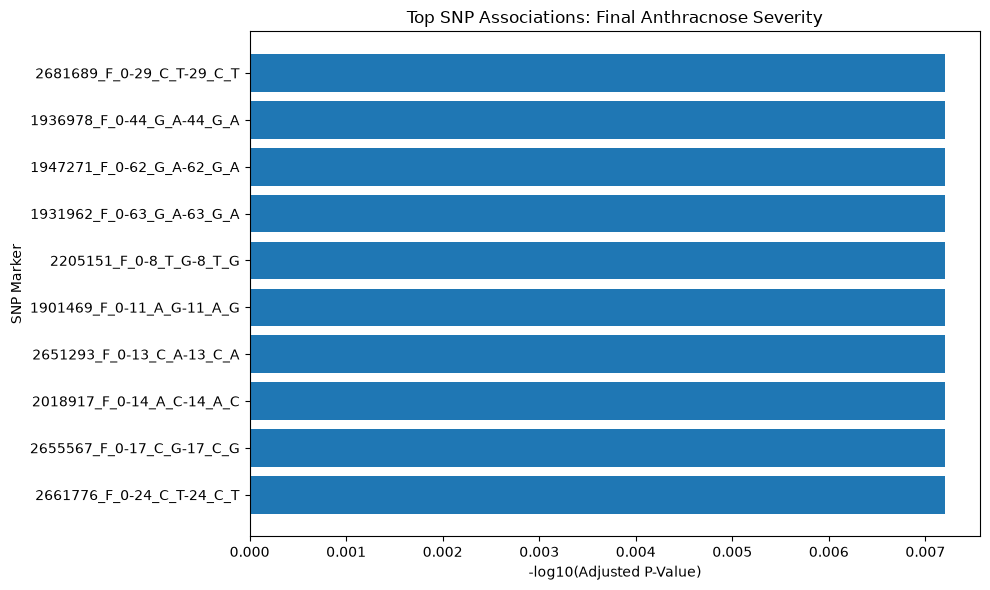

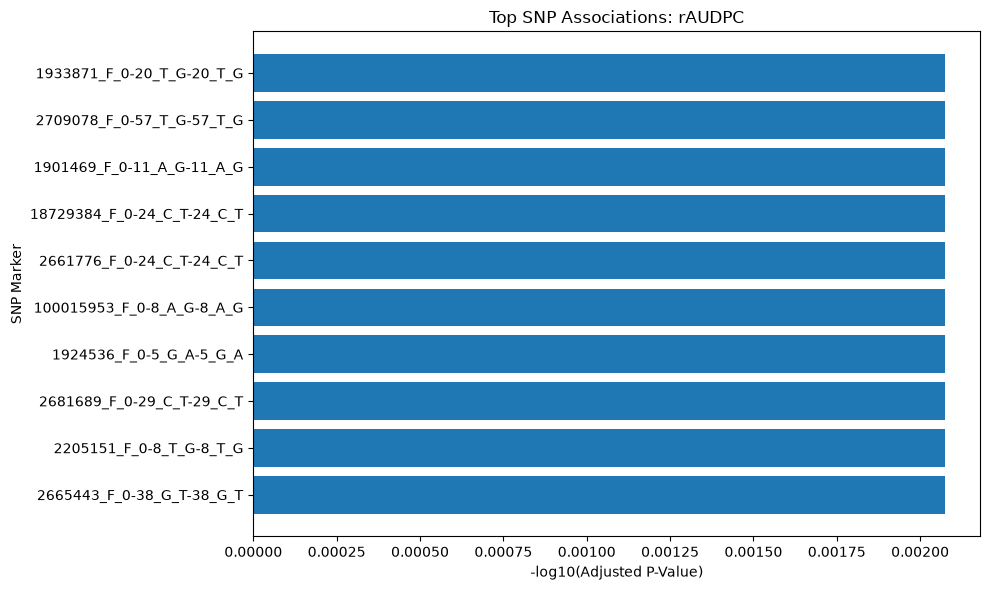

In [16]:
# 6. VISUALIZE TOP SNP ASSOCIATIONS
if not association_df.empty:
    for trait in required_traits:
        top = association_df[association_df["Trait"] == trait].head(10).copy()

        if not top.empty:
            top["-log10_adjusted_p"] = -np.log10(
                top["Adjusted_P_Value"].clip(lower=1e-300)
            )

            top = top.sort_values("-log10_adjusted_p")

            plt.figure(figsize=(10, 6))
            plt.barh(top["SNP_Marker"], top["-log10_adjusted_p"])
            plt.xlabel("-log10(Adjusted P-Value)")
            plt.ylabel("SNP Marker")
            plt.title("Top SNP Associations: " + trait)
            plt.tight_layout()
            plt.show()



Top Marker: 2661776_F_0-24_C_T-24_C_T
                           count       mean  median
2661776_F_0-24_C_T-24_C_T                          
CT                            36  37.350000    35.5
TT                            61  39.790164    39.2
CC                           176  44.652841    45.5


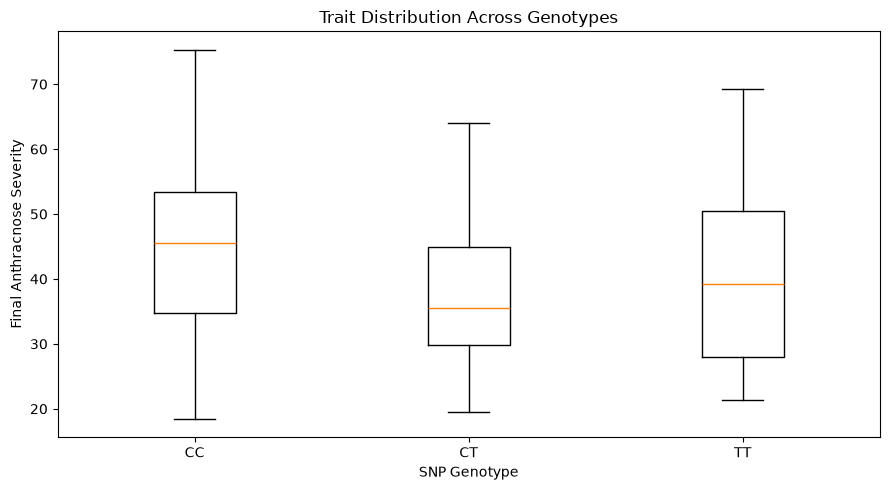


Top Marker: 2665443_F_0-38_G_T-38_G_T
                           count       mean  median
2665443_F_0-38_G_T-38_G_T                          
GT                            29  41.827586    40.0
TT                            73  44.821918    42.0
GG                           163  50.220859    49.0


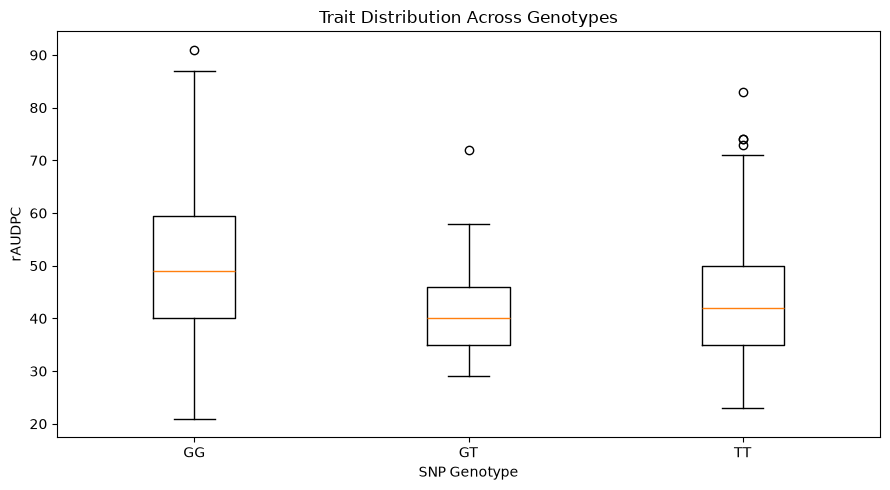

In [17]:
# 7. EXPLORE TOP MARKER GENOTYPES
if not association_df.empty:
    for trait in required_traits:
        top = association_df[association_df["Trait"] == trait]

        if top.empty:
            continue

        marker = top.iloc[0]["SNP_Marker"]
        data = df[[marker, trait]].dropna()

        summary = data.groupby(marker)[trait].agg(
            ["count", "mean", "median"]
        ).sort_values("mean")

        print("\nTop Marker:", marker)
        print(summary)

        groups = [g[trait].values for _, g in data.groupby(marker)]
        labels = [str(g) for g, _ in data.groupby(marker)]

        plt.figure(figsize=(9, 5))
        plt.boxplot(groups, tick_labels=labels)
        plt.xlabel("SNP Genotype")
        plt.ylabel(trait)
        plt.title("Trait Distribution Across Genotypes")
        plt.tight_layout()
        plt.show()


RANDOM FOREST REGRESSION
Training Samples: 233
Testing Samples: 78
MAE: 10.919
R-Squared: -0.031


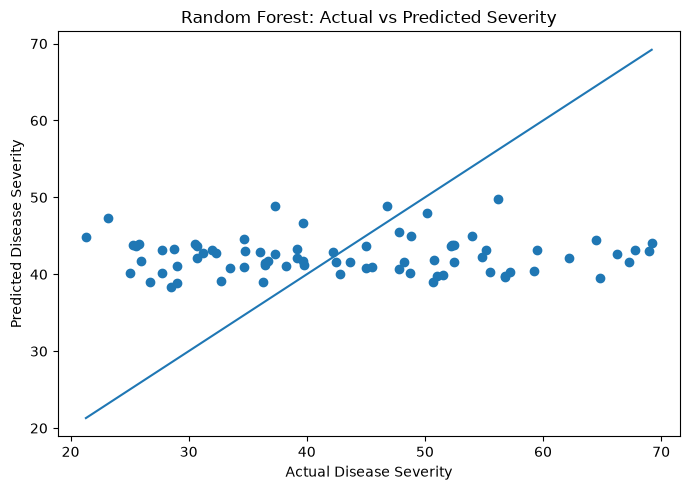

In [18]:
# 8. RANDOM FOREST REGRESSION
target = "Final Anthracnose Severity"
model_data = df.dropna(subset=[target]).copy()

if len(model_data) >= 30 and marker_columns:
    X = model_data[marker_columns].astype(object)
    X = X.where(pd.notna(X), np.nan)
    X = X.apply(lambda col: col.map(
        lambda v: str(v).strip().upper() if pd.notna(v) else np.nan
    ))
    y = model_data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    imputer = SimpleImputer(strategy="most_frequent")
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    encoder = OneHotEncoder(handle_unknown="ignore")
    X_train = encoder.fit_transform(X_train)
    X_test = encoder.transform(X_test)

    model = RandomForestRegressor(
        n_estimators=100, random_state=42,
        n_jobs=-1, max_features="sqrt"
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\nRANDOM FOREST REGRESSION")
    print("Training Samples:", len(y_train))
    print("Testing Samples:", len(y_test))
    print("MAE:", round(mean_absolute_error(y_test, predictions), 3))
    print("R-Squared:", round(r2_score(y_test, predictions), 3))

    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, predictions)

    low = min(y_test.min(), predictions.min())
    high = max(y_test.max(), predictions.max())

    plt.plot([low, high], [low, high])
    plt.xlabel("Actual Disease Severity")
    plt.ylabel("Predicted Disease Severity")
    plt.title("Random Forest: Actual vs Predicted Severity")
    plt.tight_layout()
    plt.show()

else:
    print("Not enough samples or markers for prediction.")

In [19]:
# 9. SAVE RESULTS
df.to_csv("agricultural_genomics_cleaned.csv", index=False)

print("\nAssignment 4 Analysis Completed")
print("Saved: agricultural_genomics_cleaned.csv")

if not association_df.empty:
    print("Saved: snp_trait_association_results.csv")


Assignment 4 Analysis Completed
Saved: agricultural_genomics_cleaned.csv
Saved: snp_trait_association_results.csv
